# 📝 EDA Worksheet — Auto-MPG Dataset
**Student Name:** Ahmad Ali  |  **Date:** _______________

Complete every `# TODO` cell. Run the cells in order.  
Answer the written questions in the Markdown cells provided.

---
**Dataset:** Auto-MPG (UCI) | 398 rows × 9 columns


## Task 1 — Import Libraries

In [ ]:
# TODO: Import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

# Also set sns theme to 'whitegrid' and default figure size to (10,5)
# Visual Settings
sns.set_theme (style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10,5)
pd.set_option('display.max_columns', None)
print("Libraries loaded \u2713")


Libraries loaded ✓


## Task 2 — Load & Inspect Data

In [ ]:
# TODO: Load the Auto-MPG dataset from the UCI repository URL below.
# Column names: ['mpg','cylinders','displacement','horsepower','weight',
#                'acceleration','model_year','origin','car_name']
# Missing values are marked with '?'
# URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
col_names = ['mpg','cylinders','displacement','horsepower','weight',
             'acceleration','model_year','origin','car_name']

# TODO: read_csv with correct separator (\s+) and na_values
df = pd.read_csv(
    url,
    sep=r'\s+',
    names=col_names,
    na_values='?'
)

print("Shape:", df.shape)
df.head()


Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [ ]:
# TODO: Print df.info() to inspect dtypes and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB


In [ ]:
# TODO: Print df.describe() to view summary statistics
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


**Q1.** How many rows and columns does the dataset have?  
**Answer:** 398 rows and 9 columns.

**Q2.** Which column contains missing values and how many?  
**Answer:** Horsepower contains 6 missing values.


## Task 3 — Pre-Processing

In [ ]:
# TODO: Check and print missing values per column
print("Missing values per column:")
print(df.isnull().sum())

# Then drop all rows that contain NaN values (they are < 2% of data)
df = df.dropna().reset_index(drop=True)
print("\nShape after dropping NaN:", df.shape)

Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Shape after dropping NaN: (392, 9)


In [ ]:
# TODO: Check for and remove duplicate rows
print("\nDuplicate rows before removal:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after removal:", df.duplicated().sum())
print("Final shape:", df.shape)



Duplicate rows before removal: 0
Duplicate rows after removal: 0
Final shape: (392, 9)


In [ ]:
# TODO:
# 1. Convert 'cylinders' and 'model_year' to category dtype
df['cylinders'] = df['cylinders'].astype('category')
df['model_year'] = df['model_year'].astype('category')

# 2. Map 'origin' from {1,2,3} to {'usa','europe','japan'}
df['origin'] = df['origin'].map({
    1: 'usa',
    2: 'europe',
    3: 'japan'
})

# 3. Strip & lowercase 'car_name'
df['car_name'] = df['car_name'].str.strip().str.lower()


In [ ]:
# TODO: Create two lists:
# cat_cols — categorical column names (cylinders, origin, model_year)
# num_cols — numerical column names (mpg, displacement, horsepower, weight, acceleration)

# fill in
cat_cols = ['cylinders', 'origin', 'model_year']   # fill in

# fill in
num_cols = [
    'mpg',
    'displacement',
    'horsepower',
    'weight',
    'acceleration'
]

print("\nCategorical columns:", cat_cols)
print("Numerical columns:", num_cols)


Categorical columns: ['cylinders', 'origin', 'model_year']
Numerical columns: ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']


## Task 4 — Feature Engineering

In [ ]:
# TODO: Create 'mpg_level' column using pd.cut()
# Bins: [0,17) → 'low', [17,29) → 'medium', [29, max] → 'high'
df['mpg_level'] = pd.cut(
    df['mpg'],
    bins=[0, 17, 29, np.inf],
    labels=['low', 'medium', 'high'],
    right=False
)

In [ ]:
# TODO: Create 'car_company' by extracting the first word from 'car_name'
df['car_company'] = df['car_name'].str.split().str[0]

print(df[['mpg', 'mpg_level', 'car_name', 'car_company']].head())


    mpg mpg_level                   car_name car_company
0  18.0    medium  chevrolet chevelle malibu   chevrolet
1  15.0       low          buick skylark 320       buick
2  18.0    medium         plymouth satellite    plymouth
3  16.0       low              amc rebel sst         amc
4  17.0    medium                ford torino        ford


## Task 5 — Categorical EDA

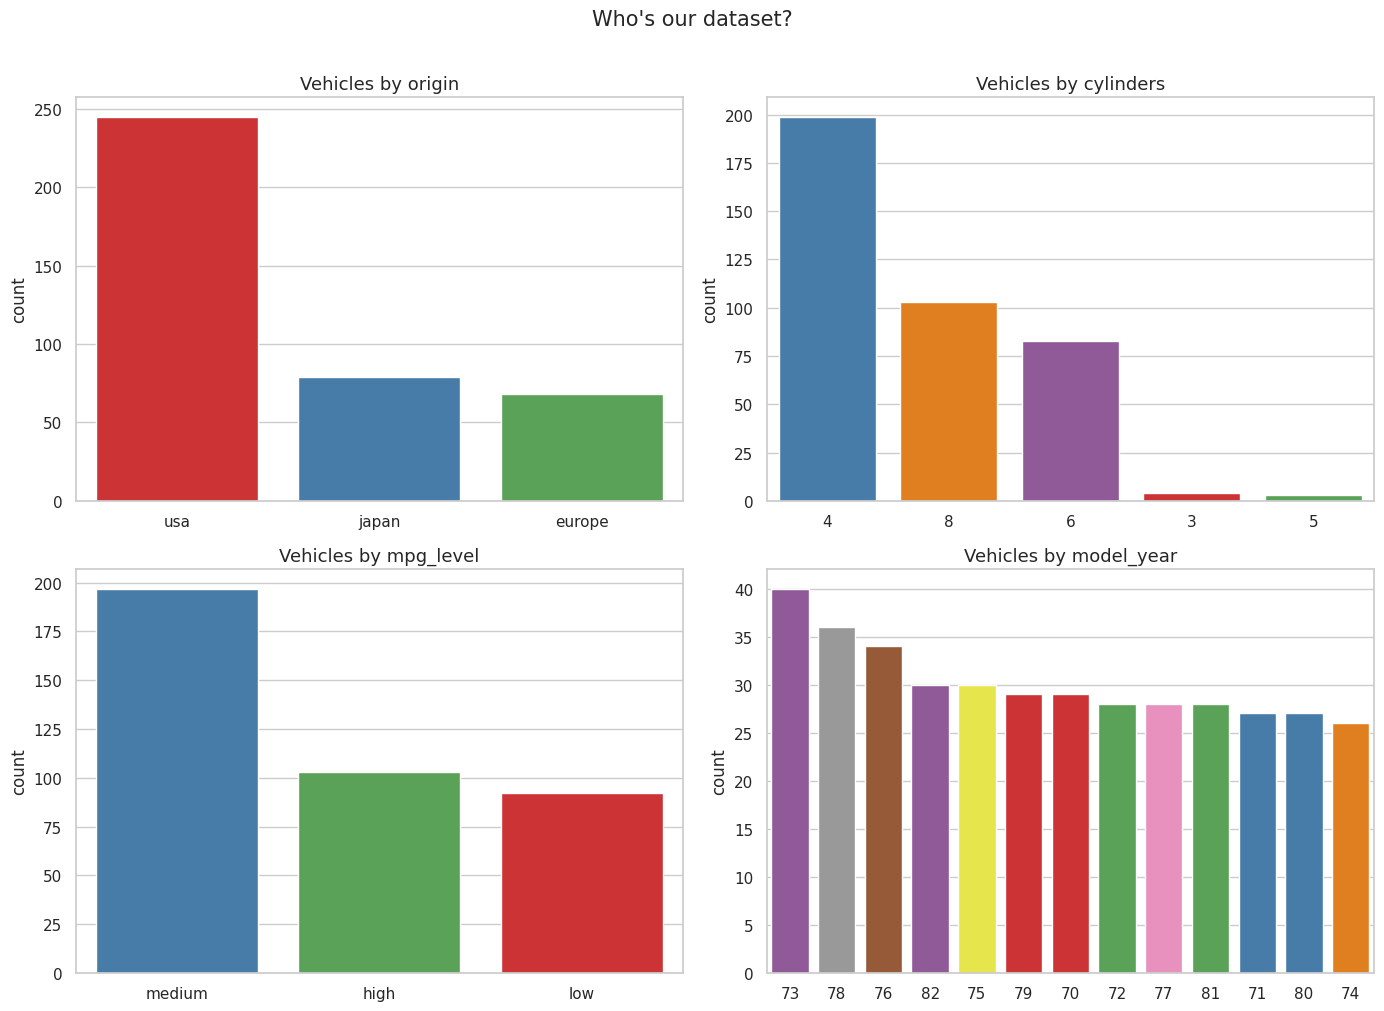

In [ ]:
# TODO: Plot a countplot for each of: origin, cylinders, mpg_level, model_year
# Arrange them in a 2×2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, ['origin', 'cylinders', 'mpg_level', 'model_year']):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set1', hue=col, legend=False)
    ax.set_title(f'Vehicles by {col}', fontsize=13)
    ax.set_xlabel('')

plt.suptitle("Who's our dataset?", fontsize=15, y=1.01)
plt.tight_layout(); plt.show()

In [ ]:
# TODO: Print the proportion (%) of the dominant class for
# origin, cylinders, and mpg_level
for col in ['origin', 'cylinders', 'mpg_level']:
    proportions = df[col].value_counts(normalize=True) * 100
    dominant_class = proportions.idxmax()
    dominant_percentage = proportions.max()

    print(
        f"{col}: {dominant_class} = "
        f"{dominant_percentage:.2f}%"
    )


origin: usa = 62.50%
cylinders: 4 = 50.77%
mpg_level: medium = 50.26%


origin     europe  japan  usa
cylinders                    
3               0      4    0
4              61     69   69
5               3      0    0
6               4      6   73
8               0      0  103


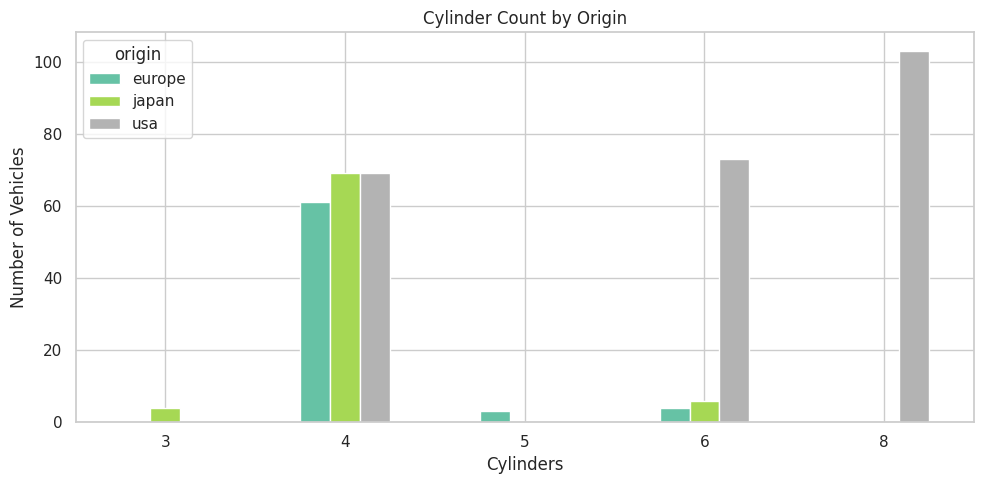

In [ ]:
# TODO: Create a crosstab of cylinders vs origin and visualise as a bar chart
cylinder_origin = pd.crosstab(
    df['cylinders'],
    df['origin']
)

print(cylinder_origin)

cylinder_origin.plot(
    kind='bar',
    figsize=(10, 5),
    colormap='Set2'
)

plt.title('Cylinder Count by Origin')
plt.xlabel('Cylinders')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


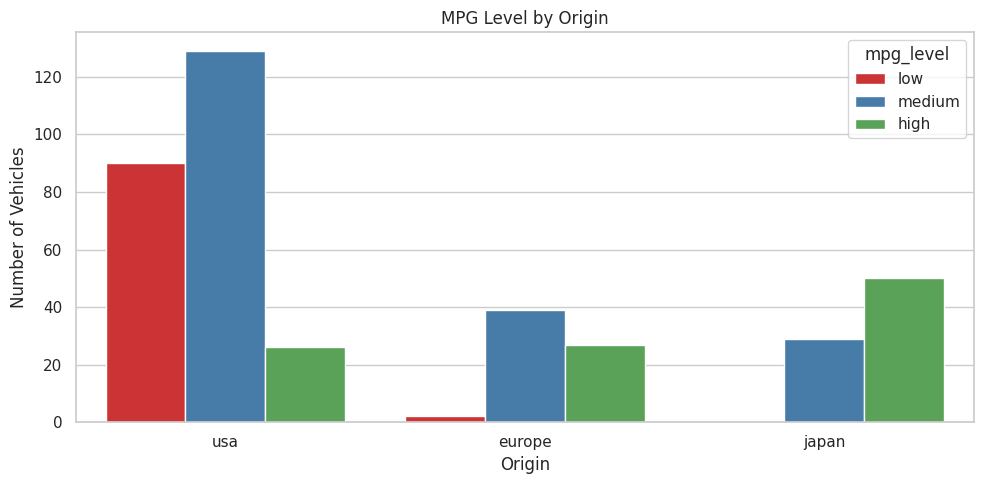

In [ ]:
# TODO: Plot a countplot of mpg_level grouped by origin (use hue='mpg_level')
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='origin',
    hue='mpg_level',
    order=['usa', 'europe', 'japan'],
    hue_order=['low', 'medium', 'high'],
    palette='Set1'
)

plt.title('MPG Level by Origin')
plt.xlabel('Origin')
plt.ylabel('Number of Vehicles')
plt.tight_layout()
plt.show()


**Q3.** Which origin has **no** vehicles with low mpg_level?  
**Answer:** Japan.

**Q4.** Which cylinder count is most common, and what percentage does it represent?  
**Answer:** 4 cylinders, approximately 50% of the cleaned dataset.


## Task 6 — Numerical EDA

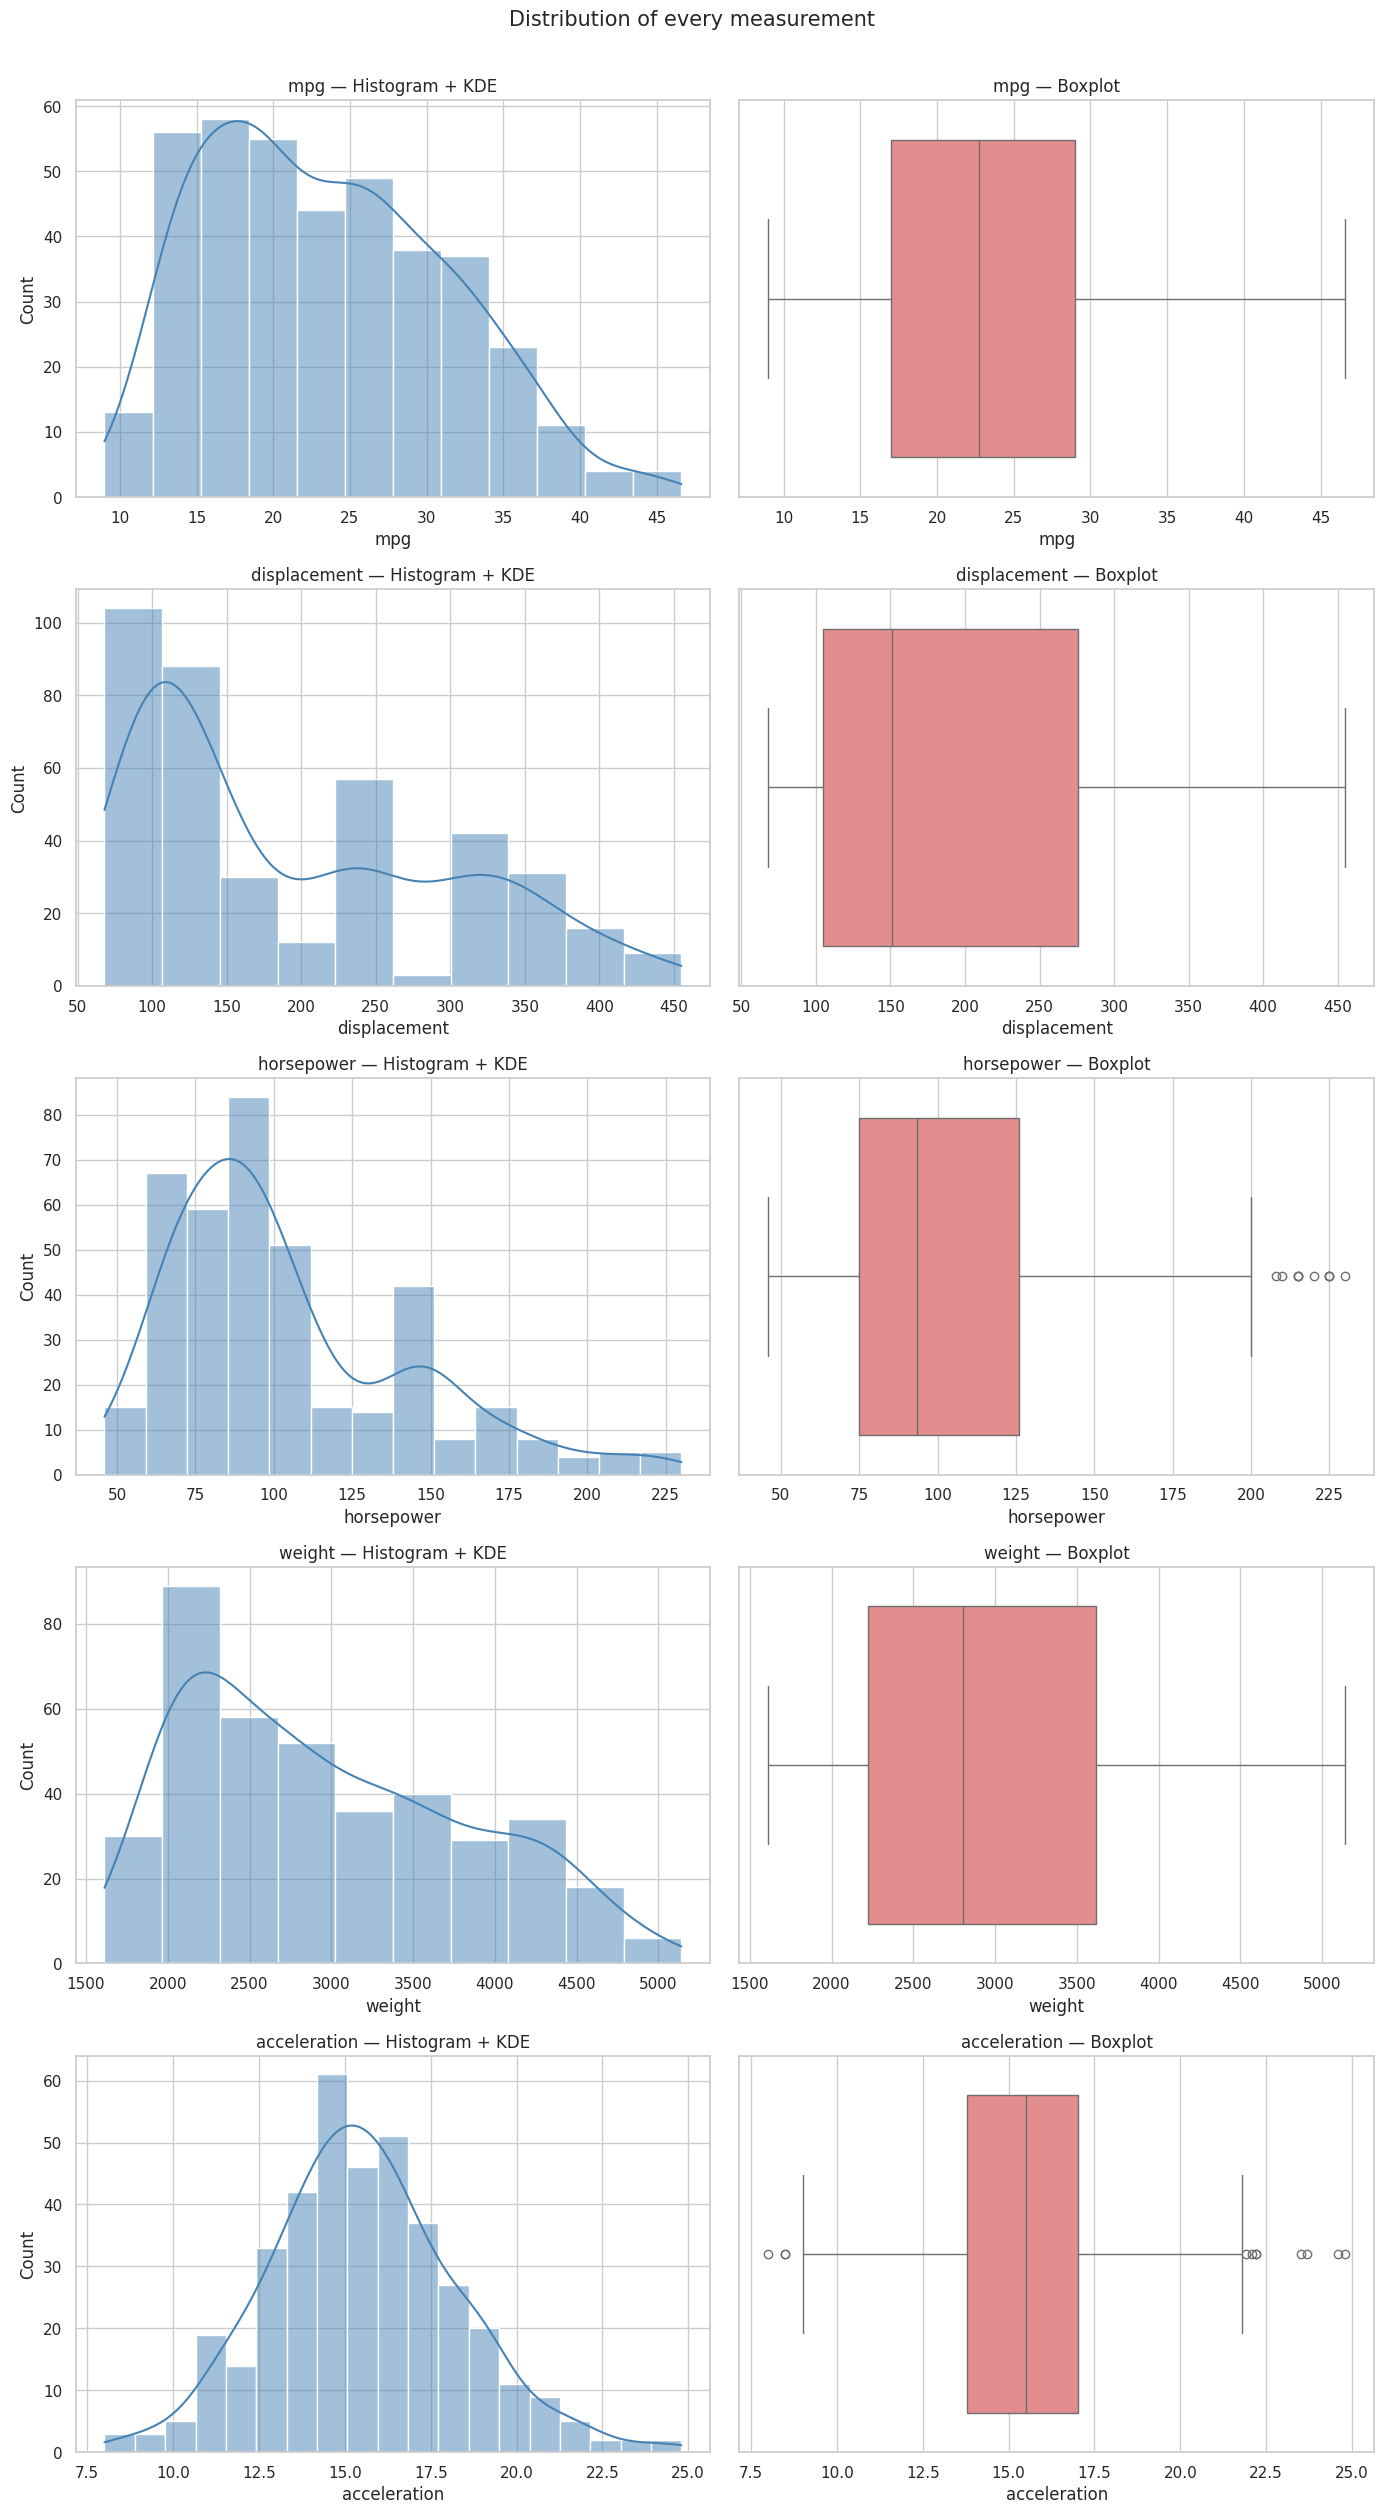

In [ ]:
# TODO: For each numerical column plot:
#   (a) Histogram + KDE  (b) Boxplot
# Arrange in a grid (n_cols rows × 2 columns)
fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 5 * len(num_cols)))

for i, col in enumerate(num_cols):

    # Histogram + KDE
    sns.histplot(data=df, x=col, kde=True, ax=axes[i, 0], color='steelblue')
    axes[i, 0].set_title(f'{col} — Histogram + KDE')

    # Boxplot
    sns.boxplot(data=df, x=col, ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'{col} — Boxplot')

plt.suptitle('Distribution of every measurement', fontsize=15, y=1.005)
plt.tight_layout()
plt.show()


In [ ]:
# TODO: Write a function tukey_outliers(series) that returns the outlier values
# using the IQR (Tukey) rule: Q1 - 1.5*IQR  and  Q3 + 1.5*IQR
# Then print the outlier count for each numerical column

def tukey_outliers(series):
    # TODO: implement
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    return series[(series < lower_bound) | (series > upper_bound)]

print("(Unusual cars per measurement === Outliers)")
for col in num_cols:
  outliers = tukey_outliers(df[col])

  print(
      f"{col}: {len(outliers)}"
  )



(Unusual cars per measurement === Outliers)
mpg: 0
displacement: 0
horsepower: 10
weight: 0
acceleration: 11


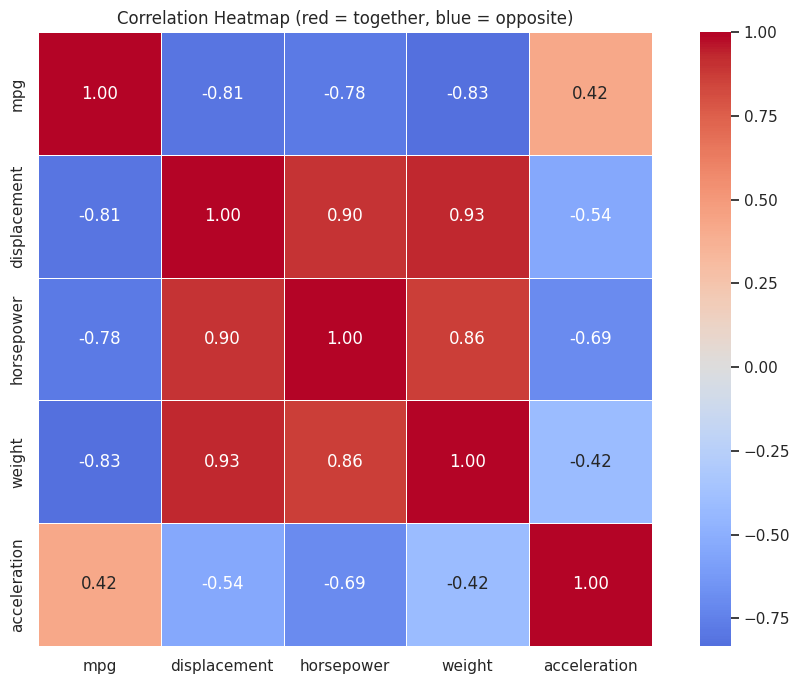

In [ ]:
# TODO: Plot a correlation heatmap for all numerical columns (use annot=True)
plt.figure(figsize=(10, 7))

corr = df[num_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    linewidths=0.5,
    square=True
)

plt.title('Correlation Heatmap (red = together, blue = opposite)')
plt.tight_layout()
plt.show()

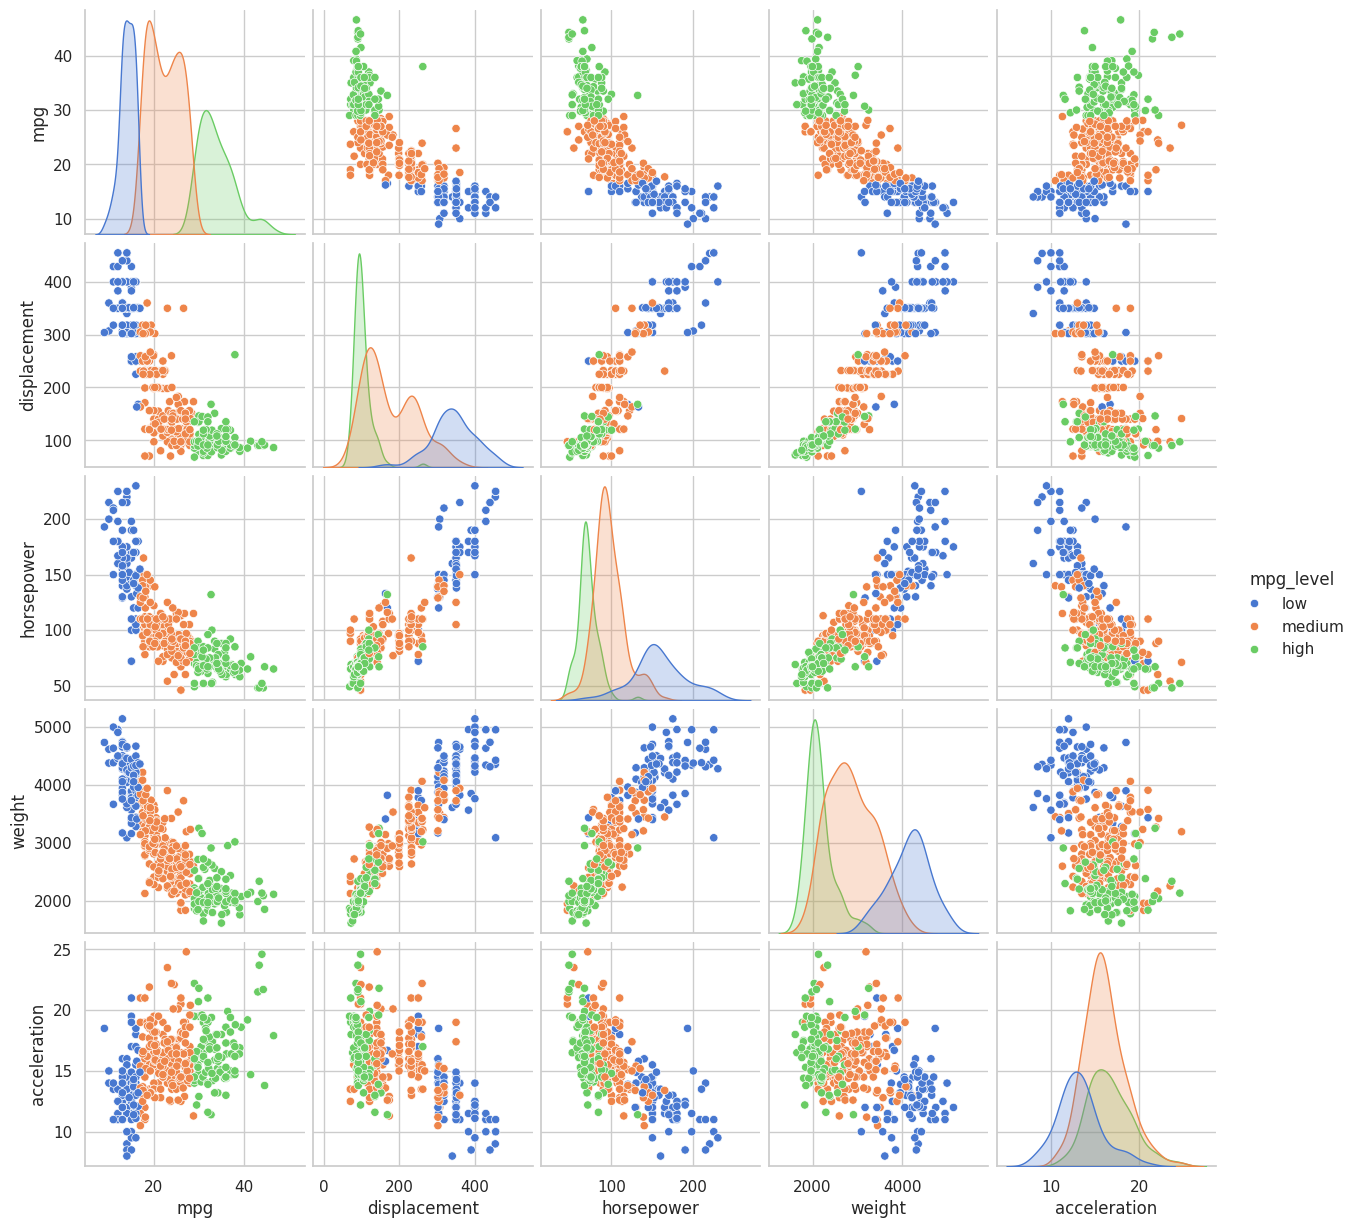

In [ ]:
# TODO: Create a pairplot of numerical columns, coloured by mpg_level
sns.pairplot(
    df,
    vars=num_cols,
    hue='mpg_level'
)

plt.show()


**Q5.** Which two numerical features have the strongest negative correlation with mpg?  
**Answer:** weight and displacement.

**Q6.** Is the `acceleration` distribution approximately Gaussian? Justify briefly.  
**Answer:** Yes, approximately. The acceleration distribution is fairly bell shaped and roughly symmetric, although it is not a perfect normal distribution.


## Task 7 — Numerical vs Categorical

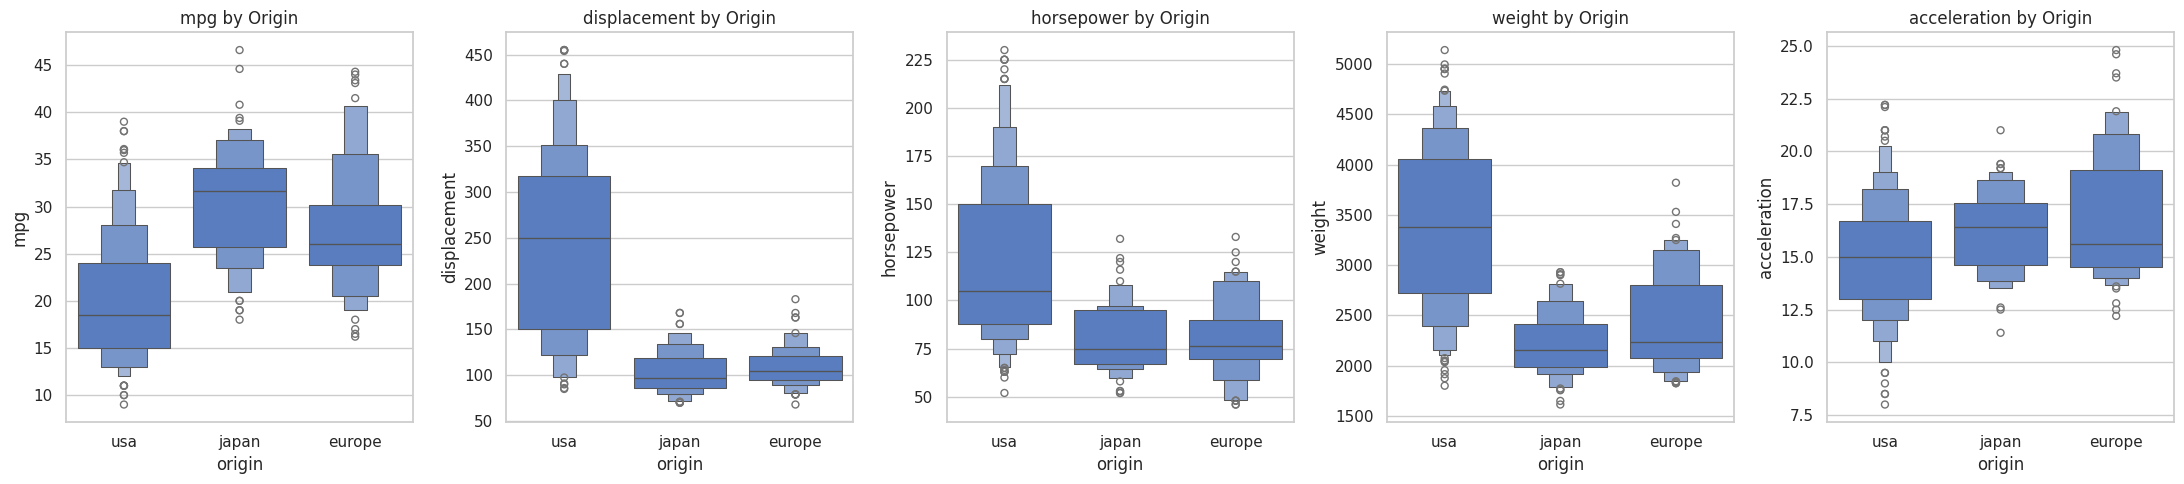

In [ ]:
# TODO: Plot boxenplots of all numerical features grouped by 'origin'
# (1 row × 5 column subplot grid)
fig, axes = plt.subplots(
    1,
    5,
    figsize=(22, 5)
)

for i, col in enumerate(num_cols):

    sns.boxenplot(
        data=df,
        x='origin',
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} by Origin')

plt.tight_layout()
plt.show()


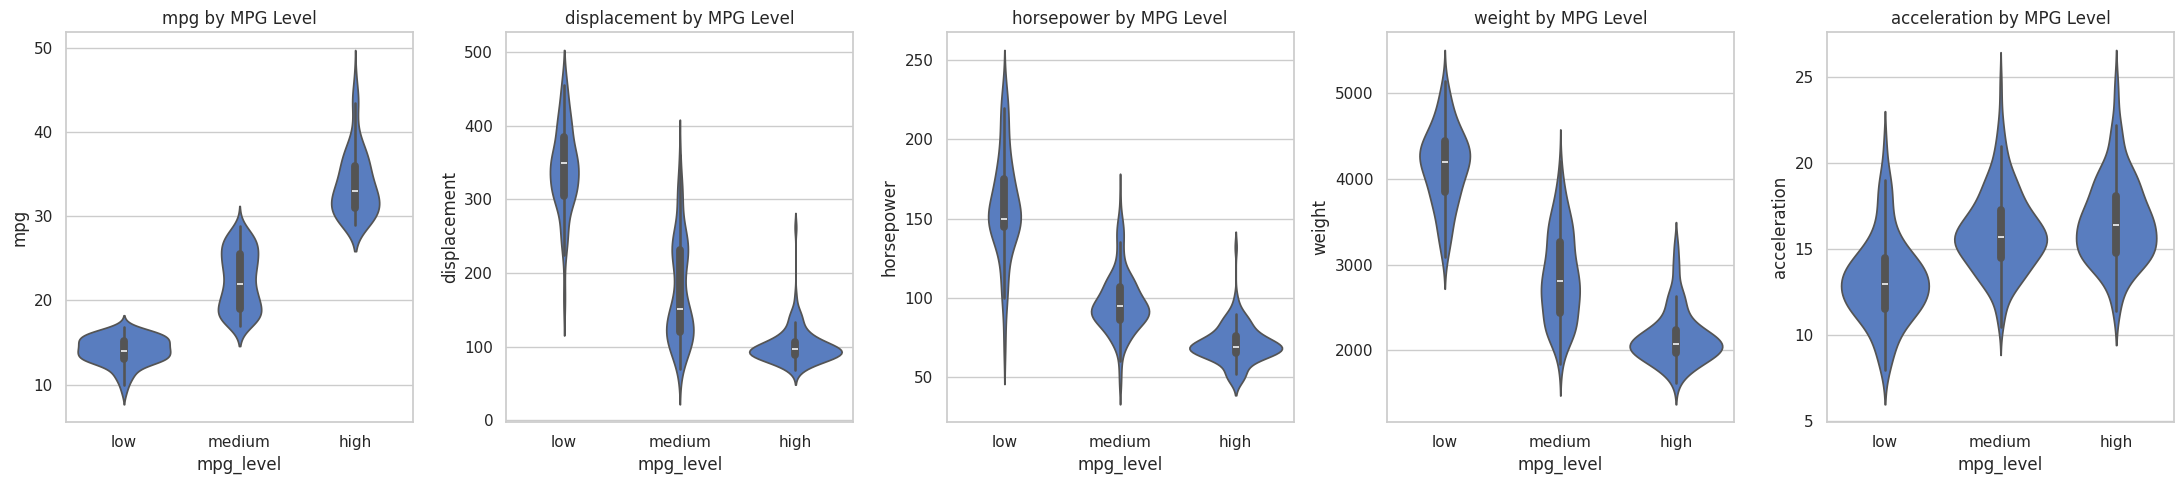

In [ ]:
# TODO: Plot violinplots of all numerical features grouped by 'mpg_level'
fig, axes = plt.subplots(
    1,
    5,
    figsize=(22, 5)
)

for i, col in enumerate(num_cols):

    sns.violinplot(
        data=df,
        x='mpg_level',
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} by MPG Level')

plt.tight_layout()
plt.show()


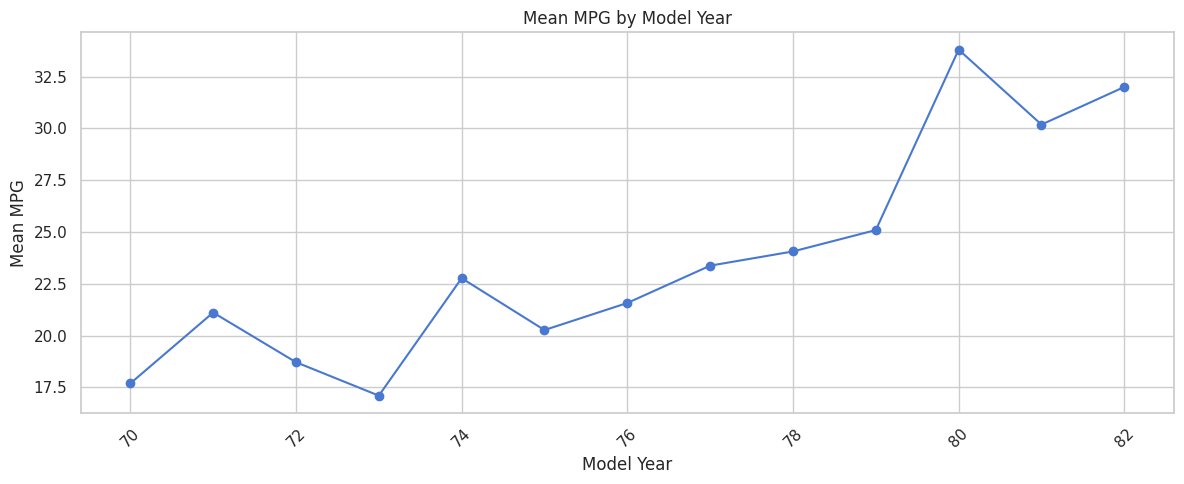

In [ ]:
# TODO: Plot a line chart showing mean mpg per model_year
mean_mpg_year = (
    df.groupby('model_year', observed=True)['mpg']
      .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    mean_mpg_year.index.astype(int),
    mean_mpg_year.values,
    marker='o'
)

plt.title('Mean MPG by Model Year')
plt.xlabel('Model Year')
plt.ylabel('Mean MPG')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


**Q7.** On average, which origin produces cars with the lowest mpg?  
**Answer:** USA

**Q8.** Describe in one sentence how mpg changes as model_year increases.  
**Answer:** MPG generally increases as model year increases, meaning newer model year cars tend to have better fuel economy.


## Task 8 — Summary Table
Fill in the table below based on your analysis.

| Feature | Relationship with MPG | Strength |
|---|---|---|
| displacement | Negative | Strong |
| horsepower | Negative | Strong |
| weight | Negative | Very Strong |
| acceleration | Positive | Moderate |
| cylinders | Negative | Strong |
| origin | Negative | Moderate |
| model_year | Positive | Moderate |
